# Next-Word Prediction on News Headlines
## Statistical Language Model (N-gram Language Model)
**An n-gram model has no neural network. It simply counts which word followed the previous 1–2 words in the training headlines, then turns the counts into probabilities.**

In [13]:
import re
import random
import pandas as pd
from collections import defaultdict, Counter
   
COLUMN   = "title"             
N        = 3                     # 3 = trigram (looks at the last 2 words). Try 2 for bigram.

# Load the dataset
df = pd.read_csv('headlines.csv')
if COLUMN not in df.columns:
    COLUMN = df.columns[0]
    print(f"Column 'title' not found, using '{COLUMN}' instead")
print("Total Rows:", len(df))
df[[COLUMN]].head()

# Clean the text
def clean(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

example = str(df[COLUMN].dropna().iloc[0])
print("Before Clean:", example)
print("After Clean:", clean(example))

# Clean the dataset
lines = [clean(t) for t in df[COLUMN].dropna()]
lines = list(dict.fromkeys(lines))                          # remove duplicates, keep order
lines = [l for l in lines if 4 <= len(l.split()) <= 25]     # keep 4–25 word headlines
print("Usable headlines:", len(lines))
lines[:3]

# Split into train and validation
random.seed(42)
random.shuffle(lines)
cut = int(len(lines) * 0.9)
train_lines, val_lines = lines[:cut], lines[cut:]
print("Train:", len(train_lines), "| Validation:", len(val_lines))

# N-gram example
demo = ["<s>"] * (N - 1) + "us economy grows fast".split()
for i in range(N - 1, len(demo)):
    print(demo[i - (N - 1): i], "->", demo[i])

# Count the n-grams 
# Every context length from 0 to N-1 (0 words = plain word frequency, 1 word = bigram, 2 words = trigram)
models = [defaultdict(Counter) for _ in range(N)]

for line in train_lines:
    toks = ["<s>"] * (N - 1) + line.split()
    for i in range(N - 1, len(toks)):
        for k in range(N):                                  # context length 0..N-1
            context = tuple(toks[i - k:i]) if k else ()
            models[k][context][toks[i]] += 1

print("Distinct contexts per order:", [len(m) for m in models])

common_word = Counter(w for l in train_lines for w in l.split()).most_common(1)[0][0]
print(f"Words that follow '{common_word}':")
models[1][(common_word,)].most_common(5)

def predict_next(seed, top_k=5):
    history = ["<s>"] * (N - 1) + clean(seed).split()
    results, seen = [], set()
    for k in range(N - 1, -1, -1):                          # longest context first
        context = tuple(history[-k:]) if k else ()
        counter = models[k].get(context)
        if not counter:
            continue
        total = sum(counter.values())
        for word, c in counter.most_common(top_k):
            if word not in seen:
                seen.add(word)
                results.append((word, c / total))
        if len(results) >= top_k:
            break
    return results[:top_k]

def show_next_words(seed, top_k=5):
    print(f"\nSeed: '{seed}'")
    for word, p in predict_next(seed, top_k):
        print(f"  {word:<15} {p:.3f}")

for seed in ["us economy", "the president", "stocks"]:
    show_next_words(seed)

# Evaluate on unseed headlines
hit1 = hit5 = total = 0
for line in val_lines:
    words = line.split()
    for i in range(1, len(words)):
        preds = [w for w, _ in predict_next(" ".join(words[:i]), 5)]
        total += 1
        hit1 += bool(preds) and preds[0] == words[i]
        hit5 += words[i] in preds

print(f"Top-1 accuracy: {hit1 / total:.3f}")
print(f"Top-5 accuracy: {hit5 / total:.3f}")

def generate(seed, n_words=8, top_k=5):
    text = clean(seed)
    for _ in range(n_words):
        preds = predict_next(text, top_k)
        if not preds:
            break
        words, probs = zip(*preds)
        text += " " + random.choices(words, weights=probs)[0]
    return text

for _ in range(3):
    print(generate("us economy"))

Total Rows: 1815
Before Clean: Election Commission to hold CEOs' conference on September 10 to discuss nationwide SIR
After Clean: election commission to hold ceos' conference on september 10 to discuss nationwide sir
Usable headlines: 1425
Train: 1282 | Validation: 143
['<s>', '<s>'] -> us
['<s>', 'us'] -> economy
['us', 'economy'] -> grows
['economy', 'grows'] -> fast
Distinct contexts per order: [1, 5142, 12361]
Words that follow 'to':

Seed: 'us economy'
  explained       0.500
  ride            0.500
  to              0.027
  in              0.019
  of              0.013

Seed: 'the president'
  macron          0.400
  donald          0.200
  jagdeep         0.200
  during          0.200
  to              0.027

Seed: 'stocks'
  in              0.500
  to              0.500
  for             0.095
  with            0.095
  surge           0.095
Top-1 accuracy: 0.140
Top-5 accuracy: 0.235
us economy explained to watch on netflix amazon prime focus
us economy explained for smart inv

# 2. Neural Network based Models 
## RNN vs LSTM vs GRU 

## Simple RNN
- A Simple RNN reads the headline one word at a time.
- At each step it mixes the current word with a hidden state (its short-term memory) and passes that state to the next step.
- The final hidden state summarises the headline so far and is used to predict the next word.

## LSTM
**An LSTM (Long Short-Term Memory) is an RNN with a separate cell state — a conveyor belt of long-term memory — controlled by three gates:**

- **forget gate:** what to erase from memory
- **input gate:** what new information to store
- **output gate:** what to expose as the hidden state
The gates let useful information survive many steps, which fixes most of the vanishing-gradient problem.

## GRU
**A GRU (Gated Recurrent Unit) is a lighter cousin of the LSTM. It merges the cell state and hidden state and uses only two gates:**

- **update gate:** how much of the old memory to keep
- **reset gate:** how much of the old memory to use when computing new information
It usually gets accuracy close to an LSTM with ~25% fewer weights and faster training.

In [ ]:
#!pip install tensorflow pandas numpy scikit-learn matplotlib

In [3]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import SparseTopKCategoricalAccuracy

COLUMN    = "title"
MAX_WORDS = 25                    # longest headline kept
MIN_COUNT = 3                     # rarer words become <OOV>

# Load and clean the data
def clean(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df = pd.read_csv('headlines.csv')
if COLUMN not in df.columns:
    COLUMN = df.columns[0]
lines = [clean(t) for t in df[COLUMN].dropna()]
lines = [l for l in dict.fromkeys(lines) if 4 <= len(l.split()) <= MAX_WORDS]

# Split into train and validation
train_lines, val_lines = train_test_split(lines, test_size=0.1, random_state=42)
print("Train:", len(train_lines), "| Validation:", len(val_lines))

# Tokenizer: words → numbers
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(train_lines)

tokenizer.num_words = sum(c >= MIN_COUNT for c in tokenizer.word_counts.values()) + 2
VOCAB  = tokenizer.num_words
OOV_ID = tokenizer.word_index["<OOV>"]
index_word = {i: w for w, i in tokenizer.word_index.items() if i < VOCAB}   # id -> word

print("Vocabulary size:", VOCAB)

# --- prefix -> next-word samples, left-padded ---
def make_xy(texts):
    seqs = []
    for line in texts:
        toks = tokenizer.texts_to_sequences([line])[0]
        seqs += [toks[:i + 1] for i in range(1, len(toks))]
    seqs = pad_sequences(seqs, maxlen=MAX_WORDS, padding="pre")
    X, y = seqs[:, :-1], seqs[:, -1]
    keep = y != OOV_ID                      # don't train on "predict <OOV>"
    return X[keep], y[keep]

X_train, y_train = make_xy(train_lines)
X_val,   y_val   = make_xy(val_lines)
INPUT_LEN = X_train.shape[1]

baseline = np.mean(y_val == np.bincount(y_train).argmax())
print(f"Headlines: {len(lines)} | vocabulary: {VOCAB} | train samples: {len(X_train)} | val samples: {len(X_val)}")
print(f"Baseline (always guess the most common word): val accuracy {baseline:.3f}")


Train: 1282 | Validation: 143
Vocabulary size: 1200
Headlines: 1425 | vocabulary: 1200 | train samples: 10096 | val samples: 1009
Baseline (always guess the most common word): val accuracy 0.048


## Model creation — what differs

All three models share the same pipeline: **Embedding → recurrent layer → Dropout → Dense (softmax)**.
Only the recurrent layer changes.

| | SimpleRNN | LSTM | GRU |
|---|---|---|---|
| Memory | one hidden state | hidden state + separate **cell state** | one hidden state |
| Gates | none | 3 (forget, input, output) | 2 (update, reset) |
| Long-range memory | weak (vanishing gradient) | strong | strong |
| Weights per unit (relative) | 1× | ~4× | ~3× |
| Speed | fastest | slowest | in between |

In [7]:
def build_model(layer_cls, units=128):
    model = Sequential([
        Input(shape=(INPUT_LEN,)),
        Embedding(VOCAB, 100, mask_zero=True),
        layer_cls(units),                      # <-- the ONLY line that differs
        Dropout(0.4),
        Dense(VOCAB, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", SparseTopKCategoricalAccuracy(k=5, name="top5_acc")])
    # model.summary()
    return model

LAYERS = {"SimpleRNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}

# parameter counts: the visible difference in model size
sizes = {name: build_model(cls).count_params() for name, cls in LAYERS.items()}
pd.DataFrame({"Total parameters": sizes})

,Total parameters
SimpleRNN,304112
LSTM,392048
GRU,363120


In [10]:
# Train the models with identical settings
models, histories, rows = {}, {}, []

for name, cls in LAYERS.items():
    tf.keras.utils.set_random_seed(42)
    model = build_model(cls)

    start = time.time()
    hist = model.fit(X_train, y_train,
                     validation_data=(X_val, y_val),
                     epochs=30, batch_size=128, verbose=1,
                     callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
    seconds = time.time() - start

    val_loss, val_acc, val_top5 = model.evaluate(X_val, y_val, verbose=0)
    models[name], histories[name] = model, hist.history
    rows.append({"Model": name,
                 "Parameters": model.count_params(),
                 "Epochs run": len(hist.history["loss"]),
                 "Train time (s)": round(seconds),
                 "Val loss": round(val_loss, 3),
                 "Perplexity": round(float(np.exp(val_loss)), 1),
                 "Val accuracy": round(val_acc, 4),
                 "Val top-5 acc": round(val_top5, 4)})
    print(f"{name:<10} done in {seconds:.0f}s")


Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.0313 - loss: 6.6772 - top5_acc: 0.0983 - val_accuracy: 0.0476 - val_loss: 6.2305 - val_top5_acc: 0.1487
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.0398 - loss: 6.3623 - top5_acc: 0.1250 - val_accuracy: 0.0476 - val_loss: 6.1765 - val_top5_acc: 0.1477
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.0431 - loss: 6.2698 - top5_acc: 0.1304 - val_accuracy: 0.0476 - val_loss: 6.1208 - val_top5_acc: 0.1596
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.0513 - loss: 6.1394 - top5_acc: 0.1462 - val_accuracy: 0.0476 - val_loss: 6.0532 - val_top5_acc: 0.1724
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.0552 - loss: 5.9969 - top5_acc: 0.1618 - val_accuracy: 0.0654 - val_loss: 5.9999 - val_top5_acc: 0.1814
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.0615 - loss: 5.8406 - top5_acc: 0.1793 - val_accuracy: 0.0644 - val_loss: 5.9704 - val_top

,Parameters,Epochs run,Train time (s),Val loss,Perplexity,Val accuracy,Val top-5 acc
Model,,,,,,,
SimpleRNN,304112,17,79,5.859,350.5,0.1011,0.2190
LSTM,392048,30,247,5.783,324.6,0.0991,0.2339
GRU,363120,18,128,5.702,299.4,0.1169,0.2468


Lowest validation loss: GRU (5.702) | baseline accuracy to beat: 0.048


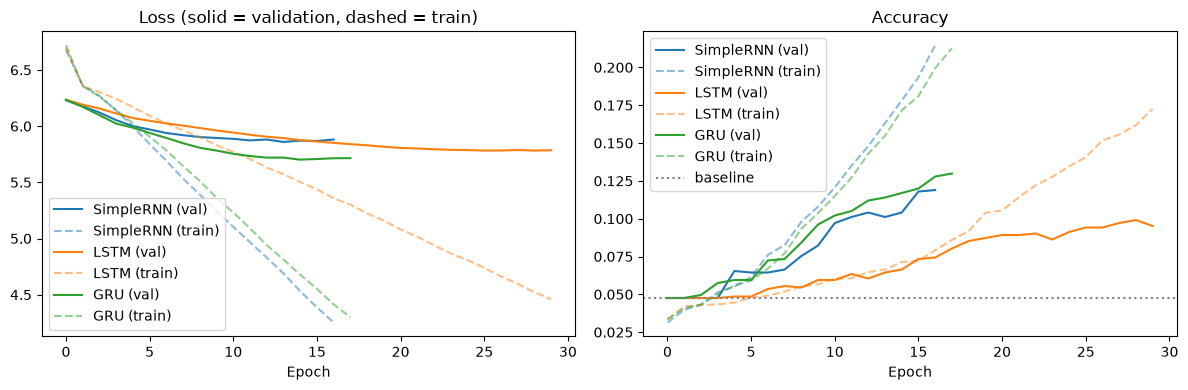

In [12]:
# Loss and Accuracy comparision
results = pd.DataFrame(rows).set_index("Model")
display(results)

best = results["Val loss"].idxmin()
print(f"Lowest validation loss: {best} ({results.loc[best, 'Val loss']}) | "
      f"baseline accuracy to beat: {baseline:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, h) in enumerate(histories.items()):
    ax[0].plot(h["val_loss"], color=f"C{i}", label=f"{name} (val)")
    ax[0].plot(h["loss"], color=f"C{i}", linestyle="--", alpha=0.5, label=f"{name} (train)")
    ax[1].plot(h["val_accuracy"], color=f"C{i}", label=f"{name} (val)")
    ax[1].plot(h["accuracy"], color=f"C{i}", linestyle="--", alpha=0.5, label=f"{name} (train)")
ax[0].set_title("Loss (solid = validation, dashed = train)"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].axhline(baseline, color="gray", linestyle=":", label="baseline")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [14]:
# Prediction results - next words 
def top_words(model, seed, k=5):
    toks = tokenizer.texts_to_sequences([clean(seed)])[0]
    toks = pad_sequences([toks], maxlen=INPUT_LEN, padding="pre")
    probs = model.predict(toks, verbose=0)[0]
    probs[0] = probs[OOV_ID] = 0.0               # ignore padding and <OOV>
    probs = probs / probs.sum()
    return [f"{index_word.get(i, '?')} ({probs[i]:.2f})" for i in np.argsort(probs)[::-1][:k]]

seeds = ["us economy", "the president", "stocks", "police say"]
for seed in seeds:
    print(f"\nSeed: '{seed}'")
    display(pd.DataFrame({name: top_words(m, seed) for name, m in models.items()},
                         index=[f"#{r}" for r in range(1, 6)]))

# For each seed we show each model's 5 most likely next words with their probabilities.


Seed: 'us economy'


,SimpleRNN,LSTM,GRU
#1,eng (0.02),conjuring (0.02),review (0.02)
#2,rites (0.01),results (0.01),collection (0.01)
#3,pro (0.01),gst (0.01),images (0.01)
#4,jannik (0.01),tv (0.01),gandhi (0.01)
#5,pawan (0.01),express (0.01),office (0.01)



Seed: 'the president'


,SimpleRNN,LSTM,GRU
#1,of (0.14),on (0.01),of (0.01)
#2,as (0.03),jumps (0.01),street (0.01)
#3,to (0.02),to (0.01),s (0.01)
#4,on (0.01),7 (0.01),with (0.01)
#5,in (0.01),billion (0.01),days (0.01)



Seed: 'stocks'


,SimpleRNN,LSTM,GRU
#1,to (0.24),to (0.19),to (0.13)
#2,s (0.10),of (0.08),for (0.05)
#3,and (0.05),s (0.07),s (0.05)
#4,for (0.04),is (0.04),is (0.05)
#5,in (0.03),for (0.03),in (0.04)



Seed: 'police say'


,SimpleRNN,LSTM,GRU
#1,k (0.06),soonicorns (0.00),pro (0.02)
#2,siddique (0.03),festival (0.00),results (0.02)
#3,calculator (0.02),kohli (0.00),sundari (0.02)
#4,soonicorns (0.02),boss (0.00),wall (0.01)
#5,oswal (0.02),altman (0.00),commission (0.01)


In [16]:
# Generated headlines
def generate(model, seed, n_words=8, temperature=0.8):
    text = clean(seed)
    for _ in range(n_words):
        toks = pad_sequences(tokenizer.texts_to_sequences([text]), maxlen=INPUT_LEN, padding="pre")
        p = model.predict(toks, verbose=0)[0].astype("float64")
        p[0] = p[OOV_ID] = 0.0
        p = np.exp(np.log(p + 1e-9) / temperature)
        p /= p.sum()
        text += " " + index_word.get(int(np.random.choice(len(p), p=p)), "")
    return text

np.random.seed(7)
for name, m in models.items():
    print(f"{name:<10}", generate(m, "the president"))

SimpleRNN  the president of smart polls why max they 12 to
LSTM       the president top day 7 picks to watch check earns
GRU        the president ahead of reality you story hope in us


# Large Language Models 
## Transformer / GPT 
**Why a Transformer beats RNN / LSTM / GRU**

- It uses **self-attention:** every token can look directly at all earlier tokens at once, instead of squeezing everything through a single hidden state.
- It trains in **parallel** (no word-by-word loop), so it scales to far more data.
- It is **pre-trained**, so it needs very little of our data to do well.

In [ ]:
#!pip install torch transformers pandas scikit-learn matplotlib

In [19]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.manual_seed(42)
 
COLUMN     = "title"
MODEL_NAME = "distilgpt2"          # or "gpt2" (bigger, slower, better)
EPOCHS, BATCH_SIZE, LR, MAX_LEN = 3, 16, 5e-5, 40

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# load and split the data

df = pd.read_csv('headlines.csv')
if COLUMN not in df.columns:
    COLUMN = df.columns[0]
    print(f"Column 'title' not found, using '{COLUMN}' instead")

lines = [re.sub(r"\s+", " ", str(t)).strip() for t in df[COLUMN].dropna()]
lines = list(dict.fromkeys(lines))                          # drop duplicates
lines = [l for l in lines if 4 <= len(l.split()) <= 25]     # keep 4–25 word headlines

train_lines, val_lines = train_test_split(lines, test_size=0.1, random_state=42)
print("Headlines:", len(lines), "| Train:", len(train_lines), "| Validation:", len(val_lines))
lines[:3]

Using device: cpu
Headlines: 1429 | Train: 1286 | Validation: 143


["Election Commission to hold CEOs' conference on September 10 to discuss nationwide SIR",
 'International.(Open in new tab)',
 'Tripura’s ruling coalition at a crossroads as BJP, Tipra Motha, IPFT jostle for tribal turf']

In [20]:
# Load the pretrained tokenizer and model
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.pad_token = tok.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

C:\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DELL\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to effici

Parameters: 81,912,576


In [21]:
# Tokenization
sample = train_lines[0]
ids = tok(sample)["input_ids"]
print("Text  :", sample)
print("Tokens:", tok.convert_ids_to_tokens(ids))
print("IDs   :", ids)
print("Vocabulary size:", tok.vocab_size)

Text  : Google Pixel 10 Pro 5G: 4 reasons to buy, and 1 to skip this flagship phone
Tokens: ['Google', 'ĠPixel', 'Ġ10', 'ĠPro', 'Ġ5', 'G', ':', 'Ġ4', 'Ġreasons', 'Ġto', 'Ġbuy', ',', 'Ġand', 'Ġ1', 'Ġto', 'Ġskip', 'Ġthis', 'Ġflagship', 'Ġphone']
IDs   : [11708, 11349, 838, 1041, 642, 38, 25, 604, 3840, 284, 2822, 11, 290, 352, 284, 14267, 428, 21336, 3072]
Vocabulary size: 50257


Seed: 'US economy'
  '.'             0.160
  ','             0.136
  ' is'           0.068
  ' and'          0.061
  ' has'          0.032


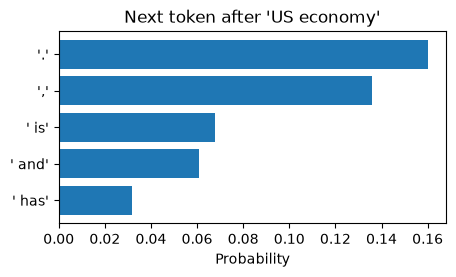

In [22]:
# Predict the next token
@torch.no_grad()
def show_next_tokens(seed, top_k=5, plot=True):
    model.eval()
    inputs = tok(seed, return_tensors="pt").to(device)
    logits = model(**inputs).logits[0, -1]              # scores for the token after the seed
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, top_k)

    print(f"Seed: '{seed}'")
    names = [tok.decode(i) for i in top.indices]
    for name, p in zip(names, top.values):
        print(f"  {name!r:<15} {p.item():.3f}")

    if plot:
        plt.figure(figsize=(5, 2.5))
        plt.barh([repr(n) for n in names][::-1], top.values.cpu().numpy()[::-1])
        plt.title(f"Next token after '{seed}'"); plt.xlabel("Probability"); plt.show()

show_next_tokens("US economy")

In [23]:
for seed in ["The president", "Stocks"]:
    show_next_tokens(seed, plot=False)

Seed: 'The president'
  ' of'           0.203
  ' and'          0.067
  ','             0.063
  ' has'          0.051
  ' is'           0.046
Seed: 'Stocks'
  '.'             0.125
  ','             0.071
  ' are'          0.049
  ' and'          0.042
  '\n'            0.025


In [24]:
# prepare the data for fine tuning
def make_loader(texts, shuffle):
    enc = tok([t + tok.eos_token for t in texts],
              truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    labels = enc["input_ids"].clone()
    labels[enc["attention_mask"] == 0] = -100
    data = TensorDataset(enc["input_ids"], enc["attention_mask"], labels)
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(train_lines, shuffle=True)
val_loader   = make_loader(val_lines,   shuffle=False)

ids, mask, labels = next(iter(train_loader))
print("Batch shapes:", ids.shape, mask.shape, labels.shape)

Batch shapes: torch.Size([16, 40]) torch.Size([16, 40]) torch.Size([16, 40])


In [26]:
# check validation loss and perplexity before fine tuning
@torch.no_grad()
def validation_loss():
    model.eval()
    losses = []
    for ids, mask, labels in val_loader:
        out = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device))
        losses.append(out.loss.item())
    return float(np.mean(losses))

before = validation_loss()
print(f"Before fine-tuning: val loss {before:.3f} | perplexity {np.exp(before):.1f}")

Before fine-tuning: val loss 5.870 | perplexity 354.3


**The training loop, in four steps per batch:**

- **Forward pass** — the model predicts and returns the loss
- **Backward pass** — compute gradients (loss.backward())
- **Clip gradients** — prevents unstable huge updates
- **Optimizer step** — update the weights, then reset the gradients

We use a small learning rate (5e-5) so we adjust the pre-trained knowledge rather than destroy it.

In [28]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
history = {"train": [], "val": []}

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []
    for ids, mask, labels in train_loader:
        out = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device))
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        optimizer.zero_grad()
        batch_losses.append(out.loss.item())

    history["train"].append(float(np.mean(batch_losses)))
    history["val"].append(validation_loss())
    print(f"Epoch {epoch + 1}/{EPOCHS} | train loss {history['train'][-1]:.3f} | "
          f"val loss {history['val'][-1]:.3f} | perplexity {np.exp(history['val'][-1]):.1f}")

Epoch 1/3 | train loss 4.877 | val loss 4.785 | perplexity 119.7
Epoch 2/3 | train loss 4.341 | val loss 4.768 | perplexity 117.7
Epoch 3/3 | train loss 3.971 | val loss 4.778 | perplexity 118.8


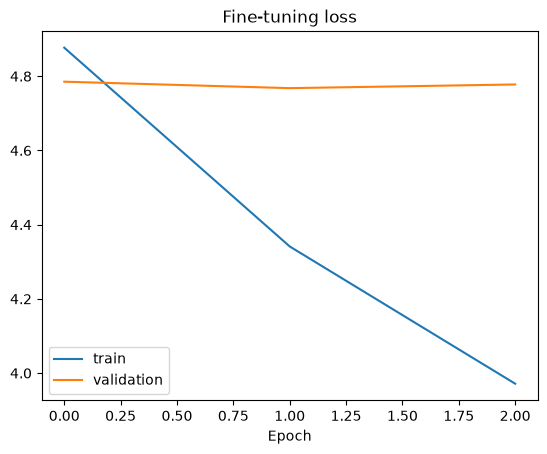

In [29]:
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.title("Fine-tuning loss"); plt.xlabel("Epoch"); plt.legend(); plt.show()

Seed: 'US economy'
  ':'             0.132
  ' data'         0.045
  ','             0.038
  ' hits'         0.030
  ' is'           0.027


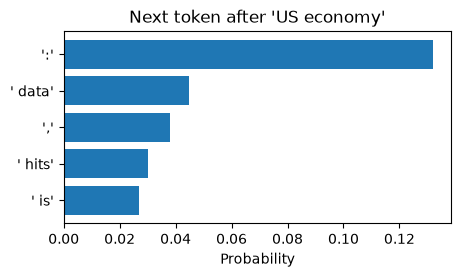

Seed: 'The president'
  ' of'           0.435
  '�'             0.075
  "'s"            0.059
  ','             0.054
  ' and'          0.036
Seed: 'Stocks'
  ' to'           0.102
  ' rally'        0.081
  ' hit'          0.030
  ' on'           0.024
  ','             0.024


In [30]:
# Predict next token after fine tuning
show_next_tokens("US economy")
for seed in ["The president", "Stocks"]:
    show_next_tokens(seed, plot=False)

In [31]:
# Generate headlines
model.eval()
for _ in range(3):
    inputs = tok("US economy", return_tensors="pt").to(device)
    out = model.generate(**inputs, max_new_tokens=12, do_sample=True, top_k=40,
                         temperature=0.8, pad_token_id=tok.eos_token_id)
    print(tok.decode(out[0], skip_special_tokens=True))

US economy signs sharp increase in US jobs report
US economy: GDP growth rate falls by 1.5 per cent in
US economy is up 2.2% in September, up 1.


In [32]:
# Save fine tuned model
model.save_pretrained("headline_gpt")
tok.save_pretrained("headline_gpt")
# Load later with: AutoModelForCausalLM.from_pretrained("headline_gpt")

Writing model shards: 100%|██████████| 1/1 [00:04<00:00,  4.18s/it]


('headline_gpt\\tokenizer_config.json', 'headline_gpt\\tokenizer.json')